# Notebook 01 — Problem and Data Understanding

## AI-Driven Public Health Surveillance Using Data Analytics

**Purpose:** Introduce the research problem, describe both datasets, inspect data quality, and produce a validated data dictionary.

**Inputs:** Raw CSV files in `data/raw/`

**Outputs:**
- Data dictionary (saved to `results/tables/`)
- Data quality report (saved to `results/tables/`)
- Target distribution chart (saved to `results/figures/`)


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from src.config import (
    PROJECT_ROOT, RANDOM_SEED, TARGET_COL, CLASS_MAP, N_CLASSES,
    DATASET1_PATH, DATASET2_PATH, RESULTS_TABLES, RESULTS_FIGURES,
)
from src.data_utils import load_dataset1, load_dataset2
from src.plotting import plot_class_distribution, save_figure, CLASS_COLOURS, CLASS_NAMES

print("Project root:", PROJECT_ROOT)
print("Random seed:", RANDOM_SEED)


Project root: d:\DAV\AI_Driven_Public_Health_Surveillance
Random seed: 42


## 1.1 Problem Statement

**Title:** AI-Driven Public Health Surveillance Using Data Analytics

**Motivation:** Diabetes is one of the most prevalent chronic diseases worldwide. Early identification of individuals' diabetes status — No Diabetes, Prediabetes, or Diabetes — can guide preventive interventions and public-health resource allocation.

**Objective:** Build an end-to-end public-health analytics system that:
1. Discovers patterns in diabetes-related health indicators (EDA).
2. Identifies factors associated with the three diabetes-status classes (Statistical Analysis + XAI).
3. Predicts an individual's estimated current diabetes status using machine learning (Predictive Analytics).
4. Places individual-level predictions in context with population-level CDC surveillance data (Surveillance).

**Primary ML Problem:** Three-class classification of `Diabetes_012`:
| Code | Status |
|------|--------|
| 0 | No Diabetes |
| 1 | Prediabetes |
| 2 | Diabetes |

> **Important:** The model predicts the *estimated current class/status* represented by the dataset. It does **not** predict whether a person will develop diabetes in the future.

**Research Hypothesis:** *A failure-aware adaptive hybrid model that learns from complementary errors, prediction confidence, and model disagreement can improve multiclass diabetes-status classification compared with individual base classifiers and conventional static ensemble approaches.*


## 1.2 Research Questions

| # | Question |
|---|----------|
| RQ1 | What health and demographic characteristics are most strongly associated with the three diabetes-status classes? |
| RQ2 | Which ML model provides the strongest overall multiclass performance? |
| RQ3 | Where does the SVM model fail? |
| RQ4 | Do other models correctly classify samples where SVM fails? |
| RQ5 | Are model errors sufficiently complementary to justify an adaptive hybrid? |
| RQ6 | Does the failure-aware hybrid outperform the strongest individual model and standard stacking? |
| RQ7 | Which components of the failure-aware system actually contribute to improvement? |
| RQ8 | Can SHAP and LIME provide understandable explanations for individual predictions? |
| RQ9 | What population-level trends are visible in the CDC surveillance dataset? |
| RQ10 | How can individual-level predictive analytics and population-level surveillance be presented together for public-health decision support? |


## 1.3 Dataset 1 — BRFSS 2015 Three-Class Diabetes Health Indicators

**Source:** CDC Behavioral Risk Factor Surveillance System (BRFSS) 2015 survey.

**Role:** Primary dataset for all individual-level analysis, feature engineering, ML modelling, explainability, and dashboard prediction.


In [2]:
# Load Dataset 1
df1 = load_dataset1()
print(f"Dataset 1 shape: {df1.shape[0]:,} rows × {df1.shape[1]} columns")
df1.head()


Dataset 1 shape: 253,680 rows × 22 columns


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0,1,1,1,40,1,0,0,0,0,...,1,0,5,18,15,1,0,9,4,3
1,0,0,0,0,25,1,0,0,1,0,...,0,1,3,0,0,0,0,7,6,1
2,0,1,1,1,28,0,0,0,0,1,...,1,1,5,30,30,1,0,9,4,8
3,0,1,0,1,27,0,0,0,1,1,...,1,0,2,0,0,0,0,11,3,6
4,0,1,1,1,24,0,0,0,1,1,...,1,0,2,3,0,0,0,11,5,4


In [3]:
# Basic info
df1.info()


<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   Diabetes_012          253680 non-null  int64
 1   HighBP                253680 non-null  int64
 2   HighChol              253680 non-null  int64
 3   CholCheck             253680 non-null  int64
 4   BMI                   253680 non-null  int64
 5   Smoker                253680 non-null  int64
 6   Stroke                253680 non-null  int64
 7   HeartDiseaseorAttack  253680 non-null  int64
 8   PhysActivity          253680 non-null  int64
 9   Fruits                253680 non-null  int64
 10  Veggies               253680 non-null  int64
 11  HvyAlcoholConsump     253680 non-null  int64
 12  AnyHealthcare         253680 non-null  int64
 13  NoDocbcCost           253680 non-null  int64
 14  GenHlth               253680 non-null  int64
 15  MentHlth              253680 non-null  int64


In [4]:
# Data types summary
dtype_summary = df1.dtypes.value_counts().rename_axis("dtype").reset_index(name="count")
print("\nData type summary:")
print(dtype_summary)



Data type summary:
   dtype  count
0  int64     22


### 1.3.1 Feature Descriptions

| Feature | Type | Description | Range |
|---------|------|-------------|-------|
| Diabetes_012 | Target | Diabetes status | 0=No, 1=Pre, 2=Yes |
| HighBP | Binary | High blood pressure | 0/1 |
| HighChol | Binary | High cholesterol | 0/1 |
| CholCheck | Binary | Cholesterol check in past 5 years | 0/1 |
| BMI | Continuous | Body Mass Index | integer |
| Smoker | Binary | Smoked ≥100 cigarettes lifetime | 0/1 |
| Stroke | Binary | Ever had a stroke | 0/1 |
| HeartDiseaseorAttack | Binary | CHD or MI | 0/1 |
| PhysActivity | Binary | Physical activity in past 30 days | 0/1 |
| Fruits | Binary | Consume fruit ≥1 time/day | 0/1 |
| Veggies | Binary | Consume vegetables ≥1 time/day | 0/1 |
| HvyAlcoholConsump | Binary | Heavy alcohol consumption | 0/1 |
| AnyHealthcare | Binary | Has healthcare coverage | 0/1 |
| NoDocbcCost | Binary | Could not see doctor due to cost | 0/1 |
| GenHlth | Ordinal | General health (1=Excellent…5=Poor) | 1–5 |
| MentHlth | Continuous | Days of poor mental health (past 30) | 0–30 |
| PhysHlth | Continuous | Days of poor physical health (past 30) | 0–30 |
| DiffWalk | Binary | Difficulty walking/climbing stairs | 0/1 |
| Sex | Binary | Sex (0=Female, 1=Male) | 0/1 |
| Age | Ordinal | 13-level age category | 1–13 |
| Education | Ordinal | Education level | 1–6 |
| Income | Ordinal | Income level | 1–8 |


### 1.3.2 Target Class Distribution

In [5]:
# Target distribution
target_counts = df1[TARGET_COL].value_counts().sort_index()
target_pcts = (target_counts / len(df1) * 100).round(2)

target_table = pd.DataFrame({
    "Class Code": target_counts.index,
    "Status": [CLASS_MAP[i] for i in target_counts.index],
    "Count": target_counts.values,
    "Percentage (%)": target_pcts.values,
})
print(target_table.to_string(index=False))

# Save
os.makedirs(RESULTS_TABLES, exist_ok=True)
target_table.to_csv(os.path.join(RESULTS_TABLES, "target_distribution.csv"), index=False)


 Class Code      Status  Count  Percentage (%)
          0 No Diabetes 213703           84.24
          1 Prediabetes   4631            1.83
          2    Diabetes  35346           13.93


Figure saved: d:\DAV\AI_Driven_Public_Health_Surveillance\results/figures\01_target_distribution.png


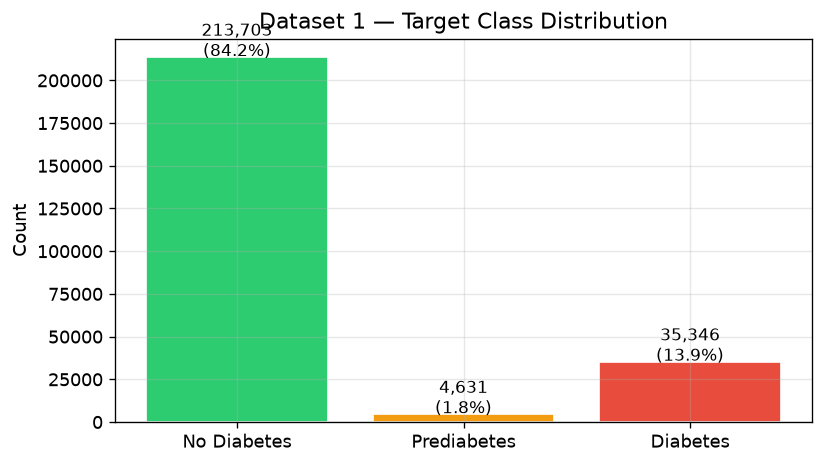

In [6]:
# Visualise target distribution
fig, ax = plot_class_distribution(df1[TARGET_COL], title="Dataset 1 — Target Class Distribution")
os.makedirs(RESULTS_FIGURES, exist_ok=True)
save_figure(fig, os.path.join(RESULTS_FIGURES, "01_target_distribution.png"))
plt.show()


**Observation:** The dataset is heavily imbalanced. Class 0 (No Diabetes) dominates with ~84.2%, while Class 1 (Prediabetes) accounts for only ~1.8%. This severe imbalance — especially the very small Prediabetes class — will require careful handling during model training.

### 1.3.3 Data Quality Assessment

In [7]:
# Missing values
missing = df1.isnull().sum()
total_missing = missing.sum()
print(f"Total missing values: {total_missing}")
if total_missing == 0:
    print("✓ No missing values found in Dataset 1.")
else:
    print(missing[missing > 0])


Total missing values: 0
✓ No missing values found in Dataset 1.


In [8]:
# Duplicate rows
n_dupes = df1.duplicated().sum()
print(f"Duplicate rows: {n_dupes:,} ({n_dupes/len(df1)*100:.2f}%)")
print()
print("Note: In survey data, duplicate rows may represent genuinely different")
print("respondents who gave identical answers. We will analyse but NOT automatically")
print("remove them without justification in Notebook 02.")


Duplicate rows: 23,899 (9.42%)

Note: In survey data, duplicate rows may represent genuinely different
respondents who gave identical answers. We will analyse but NOT automatically
remove them without justification in Notebook 02.


In [9]:
# Value range validation
range_report = []
for col in df1.columns:
    range_report.append({
        "Feature": col,
        "Min": df1[col].min(),
        "Max": df1[col].max(),
        "Unique": df1[col].nunique(),
        "Zeros": (df1[col] == 0).sum(),
    })
range_df = pd.DataFrame(range_report)
print(range_df.to_string(index=False))

# Save
range_df.to_csv(os.path.join(RESULTS_TABLES, "01_feature_ranges.csv"), index=False)


             Feature  Min  Max  Unique  Zeros
        Diabetes_012    0    2       3 213703
              HighBP    0    1       2 144851
            HighChol    0    1       2 146089
           CholCheck    0    1       2   9470
                 BMI   12   98      84      0
              Smoker    0    1       2 141257
              Stroke    0    1       2 243388
HeartDiseaseorAttack    0    1       2 229787
        PhysActivity    0    1       2  61760
              Fruits    0    1       2  92782
             Veggies    0    1       2  47839
   HvyAlcoholConsump    0    1       2 239424
       AnyHealthcare    0    1       2  12417
         NoDocbcCost    0    1       2 232326
             GenHlth    1    5       5      0
            MentHlth    0   30      31 175680
            PhysHlth    0   30      31 160052
            DiffWalk    0    1       2 211005
                 Sex    0    1       2 141974
                 Age    1   13      13      0
           Education    1    6    

In [10]:
# Descriptive statistics
desc = df1.describe().T
desc["IQR"] = desc["75%"] - desc["25%"]
print(desc.round(2).to_string())
desc.round(4).to_csv(os.path.join(RESULTS_TABLES, "01_descriptive_stats.csv"))


                         count   mean   std   min   25%   50%   75%   max  IQR
Diabetes_012          253680.0   0.30  0.70   0.0   0.0   0.0   0.0   2.0  0.0
HighBP                253680.0   0.43  0.49   0.0   0.0   0.0   1.0   1.0  1.0
HighChol              253680.0   0.42  0.49   0.0   0.0   0.0   1.0   1.0  1.0
CholCheck             253680.0   0.96  0.19   0.0   1.0   1.0   1.0   1.0  0.0
BMI                   253680.0  28.38  6.61  12.0  24.0  27.0  31.0  98.0  7.0
Smoker                253680.0   0.44  0.50   0.0   0.0   0.0   1.0   1.0  1.0
Stroke                253680.0   0.04  0.20   0.0   0.0   0.0   0.0   1.0  0.0
HeartDiseaseorAttack  253680.0   0.09  0.29   0.0   0.0   0.0   0.0   1.0  0.0
PhysActivity          253680.0   0.76  0.43   0.0   1.0   1.0   1.0   1.0  0.0
Fruits                253680.0   0.63  0.48   0.0   0.0   1.0   1.0   1.0  1.0
Veggies               253680.0   0.81  0.39   0.0   1.0   1.0   1.0   1.0  0.0
HvyAlcoholConsump     253680.0   0.06  0.23   0.0   

## 1.4 Dataset 2 — CDC Diabetes Surveillance System

**Source:** CDC Division of Diabetes Translation — Diabetes Surveillance System.

**Role:** Population-level surveillance data. Used for trend analysis, geographic/demographic comparisons, and public-health context. **NOT** merged with Dataset 1 at the record level.


In [11]:
# Load Dataset 2
df2 = load_dataset2()
print(f"Dataset 2 shape: {df2.shape[0]:,} rows × {df2.shape[1]} columns")
df2.head()


Dataset 2 shape: 13,889 rows × 16 columns


,Year,Topic,Indicator,Unit,Estimate,SE Estimate,Lower Limit,Upper Limit,Estimate Footnote,Data Source,Population,Age,Race,Sex,Education,Other Stratification
0,2000,Burden/Magnitude,Diagnosed Diabetes,Percentage,8.3,0.3,7.7,9,NaN,National Health Interview Survey (NHIS),All Ages,45-64,All,All,All,NaN
1,2000,Burden/Magnitude,Diagnosed Diabetes,Percentage,15.8,0.8,14.3,17.3,NaN,National Health Interview Survey (NHIS),All Ages,65-74,All,All,All,NaN
2,2000,Burden/Magnitude,Diagnosed Diabetes,Percentage,13.2,0.7,11.8,14.7,NaN,National Health Interview Survey (NHIS),All Ages,75+,All,All,All,NaN
3,2000,Burden/Magnitude,Diagnosed Diabetes,Percentage,1.2,0.1,1.1,1.4,NaN,National Health Interview Survey (NHIS),All Ages,0-44,All,All,All,NaN
4,2000,Burden/Magnitude,Diagnosed Diabetes,Percentage,4.4,0.1,4.2,4.6,NaN,National Health Interview Survey (NHIS),All Ages,Crude,All,All,All,NaN


In [12]:
# Dataset 2 info
df2.info()


<class 'pandas.DataFrame'>
RangeIndex: 13889 entries, 0 to 13888
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Year                  13889 non-null  int64  
 1   Topic                 13889 non-null  str    
 2   Indicator             13889 non-null  str    
 3   Unit                  13889 non-null  str    
 4   Estimate              13370 non-null  str    
 5   SE Estimate           11546 non-null  float64
 6   Lower Limit           11546 non-null  str    
 7   Upper Limit           11546 non-null  str    
 8   Estimate Footnote     519 non-null    str    
 9   Data Source           13889 non-null  str    
 10  Population            13889 non-null  str    
 11  Age                   13889 non-null  str    
 12  Race                  13889 non-null  str    
 13  Sex                   13889 non-null  str    
 14  Education             13889 non-null  str    
 15  Other Stratification  7150 non

In [13]:
# Dataset 2 — column inspection
for col in df2.columns:
    print(f"\n{'='*50}")
    print(f"Column: {col}")
    print(f"  dtype: {df2[col].dtype}")
    print(f"  missing: {df2[col].isnull().sum()}")
    print(f"  unique: {df2[col].nunique()}")
    if df2[col].nunique() <= 20:
        print(f"  values: {sorted(df2[col].dropna().unique())}")



Column: Year
  dtype: int64
  missing: 0
  unique: 25

Column: Topic
  dtype: str
  missing: 0
  unique: 1
  values: ['Burden/Magnitude']

Column: Indicator
  dtype: str
  missing: 0
  unique: 6
  values: ['Age at Diagnosis of Diabetes', 'Diagnosed Diabetes', 'Diagnosed Type 1 Diabetes', 'Diagnosed Type 2 Diabetes', 'Duration of Diabetes', 'Newly Diagnosed Diabetes']

Column: Unit
  dtype: str
  missing: 0
  unique: 4
  values: ['Number in 1,000,000s', 'Number in 1,000s', 'Percentage', 'Rate per 1,000']

Column: Estimate
  dtype: str
  missing: 519
  unique: 3077

Column: SE Estimate
  dtype: float64
  missing: 2343
  unique: 517

Column: Lower Limit
  dtype: str
  missing: 2343
  unique: 2331

Column: Upper Limit
  dtype: str
  missing: 2343
  unique: 2595

Column: Estimate Footnote
  dtype: str
  missing: 13370
  unique: 1
  values: ['Suppressed']

Column: Data Source
  dtype: str
  missing: 0
  unique: 2
  values: ['100% Medicare fee-for-service claims', 'National Health Interview 

In [14]:
# Dataset 2 — year range
print(f"Year range: {df2['Year'].min()} – {df2['Year'].max()}")
print(f"Topics: {df2['Topic'].unique()}")
print(f"Indicators: {df2['Indicator'].unique()}")
print(f"Populations: {df2['Population'].unique()}")


Year range: 2000 – 2024
Topics: <ArrowStringArray>
['Burden/Magnitude']
Length: 1, dtype: str
Indicators: <ArrowStringArray>
[          'Diagnosed Diabetes', 'Age at Diagnosis of Diabetes',
    'Diagnosed Type 1 Diabetes',    'Diagnosed Type 2 Diabetes',
         'Duration of Diabetes',     'Newly Diagnosed Diabetes']
Length: 6, dtype: str
Populations: <ArrowStringArray>
[                                        'All Ages',
              'Adults with Diabetes Aged 18+ Years',
                            'Adults Aged 18+ Years',
               'Adults Aged 18+ Years: Single Year',
            'Adults Aged 18+ Years: 3-Year Average',
 'Medicare fee-for-service beneficiaries 67+ Years']
Length: 6, dtype: str


## 1.5 Data Quality Summary

In [15]:
# Create data quality report
quality_report = {
    "Check": [
        "Total observations (Dataset 1)",
        "Total features (Dataset 1)",
        "Target column",
        "Number of classes",
        "Missing values",
        "Duplicate rows",
        "Data types",
        "BMI range",
        "Age range (ordinal)",
        "Dataset 2 observations",
        "Dataset 2 year span",
    ],
    "Result": [
        f"{df1.shape[0]:,}",
        f"{df1.shape[1] - 1}",
        TARGET_COL,
        str(N_CLASSES),
        "None" if total_missing == 0 else str(total_missing),
        f"{n_dupes:,} ({n_dupes/len(df1)*100:.1f}%)",
        "All int64 (integer-coded)",
        f"{df1['BMI'].min()} – {df1['BMI'].max()}",
        f"{df1['Age'].min()} – {df1['Age'].max()}",
        f"{df2.shape[0]:,}",
        f"{df2['Year'].min()} – {df2['Year'].max()}",
    ],
    "Action Needed": [
        "No", "No", "No", "No",
        "No — no missingness",
        "Investigate in NB02",
        "No", "Validate extremes in NB02",
        "No", "No", "No",
    ]
}
quality_df = pd.DataFrame(quality_report)
print(quality_df.to_string(index=False))
quality_df.to_csv(os.path.join(RESULTS_TABLES, "01_data_quality_report.csv"), index=False)
print("\n✓ Data quality report saved.")


                         Check                    Result             Action Needed
Total observations (Dataset 1)                   253,680                        No
    Total features (Dataset 1)                        21                        No
                 Target column              Diabetes_012                        No
             Number of classes                         3                        No
                Missing values                      None       No — no missingness
                Duplicate rows             23,899 (9.4%)       Investigate in NB02
                    Data types All int64 (integer-coded)                        No
                     BMI range                   12 – 98 Validate extremes in NB02
           Age range (ordinal)                    1 – 13                        No
        Dataset 2 observations                    13,889                        No
           Dataset 2 year span               2000 – 2024                        No

✓ D

## 1.6 Feature Type Summary

In [16]:
from src.data_utils import BINARY_FEATURES, ORDINAL_FEATURES, CONTINUOUS_FEATURES

feat_type_data = []
for f in BINARY_FEATURES:
    feat_type_data.append({"Feature": f, "Type": "Binary", "Range": "0/1"})
for f in ORDINAL_FEATURES:
    feat_type_data.append({"Feature": f, "Type": "Ordinal", "Range": f"{df1[f].min()}-{df1[f].max()}"})
for f in CONTINUOUS_FEATURES:
    feat_type_data.append({"Feature": f, "Type": "Continuous", "Range": f"{df1[f].min()}-{df1[f].max()}"})

feat_type_df = pd.DataFrame(feat_type_data)
print(feat_type_df.to_string(index=False))
feat_type_df.to_csv(os.path.join(RESULTS_TABLES, "01_feature_type_summary.csv"), index=False)


             Feature       Type Range
              HighBP     Binary   0/1
            HighChol     Binary   0/1
           CholCheck     Binary   0/1
              Smoker     Binary   0/1
              Stroke     Binary   0/1
HeartDiseaseorAttack     Binary   0/1
        PhysActivity     Binary   0/1
              Fruits     Binary   0/1
             Veggies     Binary   0/1
   HvyAlcoholConsump     Binary   0/1
       AnyHealthcare     Binary   0/1
         NoDocbcCost     Binary   0/1
            DiffWalk     Binary   0/1
                 Sex     Binary   0/1
             GenHlth    Ordinal   1-5
                 Age    Ordinal  1-13
           Education    Ordinal   1-6
              Income    Ordinal   1-8
                 BMI Continuous 12-98
            MentHlth Continuous  0-30
            PhysHlth Continuous  0-30


## 1.7 Conclusion

**Key findings from data understanding:**

1. **Dataset 1** contains 253,680 survey responses with 21 health-indicator features and a three-class target (`Diabetes_012`).
2. **No missing values** exist — advanced imputation is unnecessary.
3. **23,899 duplicate rows** exist (~9.4%) — these will be investigated in Notebook 02 but may represent legitimate survey responses.
4. **Severe class imbalance** — Prediabetes (Class 1) has only ~4,631 observations (1.8%), compared to 213,703 for No Diabetes (84.2%).
5. **Dataset 2** contains 13,889 population-level surveillance records spanning multiple years, stratified by age, race, sex, and education.
6. **All features** are integer-coded (binary, ordinal, or integer-continuous) — no complex encoding is needed.

**Next:** Notebook 02 — Data Cleaning and Preprocessing

**Outputs produced:**
- `results/tables/target_distribution.csv`
- `results/tables/01_feature_ranges.csv`
- `results/tables/01_descriptive_stats.csv`
- `results/tables/01_data_quality_report.csv`
- `results/tables/01_feature_type_summary.csv`
- `results/figures/01_target_distribution.png`
